# 04 · SHAP Explanations (Q4)

**คำถามวิจัย Q4** — ฟีเจอร์ใดขับเคลื่อนการทำนาย (global) และทำไมแต่ละ record จึงถูกทำนายเช่นนั้น (local)?

**SHAP (SHapley Additive exPlanations)** มาจากทฤษฎีเกม (Shapley values):
แตกการทำนายของ record หนึ่งออกเป็น "ผลบวกของ contributions" ของแต่ละฟีเจอร์

```
prediction = base_value + Σ (SHAP value ของแต่ละฟีเจอร์)
```

- ค่า **+** → ดันความน่าจะเป็นไปทาง "เป็น stroke"
- ค่า **−** → ดันไปทาง "ไม่เป็น stroke"
- |ค่า| มาก → อิทธิพลมาก

## 0. หมายเหตุเชิงเทคนิค (สำคัญ)

เราอธิบาย **classifier บนฟีเจอร์หลัง transform** (one-hot แล้ว) ไม่ใช่ที่ตัว Pipeline ทั้งก้อน
เพราะ SHAP ต้องใช้ predict function ที่รับเมทริกซ์ตัวเลข

จากนั้นเราจึง **รวมคอลัมน์ one-hot กลับเป็น base feature**
เช่น `work_type_Private` + `work_type_Govt_job` + ... → `work_type`
เพื่อให้อ่านง่ายและเทียบกับ LIME ได้ตรงกัน (LIME ทำงานระดับ base feature)

เรายัง **ไม่ใช้ KernelExplainer** เป็นค่าเริ่มต้น เพราะช้ามากและมี variance สูง
เลือกใช้ `TreeExplainer` (สำหรับ XGBoost/LightGBM/RandomForest) และ `LinearExplainer`
(สำหรับ Logistic Regression) ซึ่งเป็น exact algorithm

## 1. โหลดโมเดลและข้อมูล

In [1]:
import sys
from pathlib import Path

# ให้ import src ได้ไม่ว่าจะเปิด notebook จากโฟลเดอร์ไหน
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("Project root:", ROOT)

Project root: D:\Stroke Prediction Dataset\Stroke-Prediction-XAI


In [2]:
def show_figure(relative_path: str, width: int = 950):
    """แสดงรูปที่ pipeline สร้างไว้ใน reports/figures"""
    path = ROOT / "reports" / "figures" / relative_path
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"[ไม่พบรูป] {path} — รัน `python -m src.run_pipeline` ก่อน")

In [3]:
import joblib
from sklearn.model_selection import train_test_split
from src import config as cfg, data_loader as dl

bundle = joblib.load(cfg.MODELS_DIR / "best_model.joblib")
model, threshold, model_name = bundle["model"], bundle["threshold"], bundle["name"]
print("โมเดล:", model_name)
print("threshold:", round(threshold, 3))

clean = dl.basic_clean(dl.load_raw())
X, y = dl.split_features_target(clean)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=cfg.TEST_SIZE, stratify=y, random_state=cfg.RANDOM_STATE)

โมเดล: LogReg (class_weight=balanced)
threshold: 0.766


## 2. คำนวณ SHAP values

ตัวอย่างนี้ใช้ test set 300 records เพื่อให้คำนวณเร็ว
(ใน pipeline เต็มใช้ 1,500 records — ดู `reports/tables/q4_shap_global_importance.csv`)

In [4]:
from src import xai

sample = X_test.sample(300, random_state=cfg.RANDOM_STATE)
X_transformed, shap_values, base_value, explainer = xai.compute_shap(model, sample, X_train)

print("รูปร่างของ SHAP matrix:", shap_values.shape)
print("  = (จำนวน records, จำนวนฟีเจอร์หลัง one-hot)")
print("base value:", base_value, "| หน่วยของค่า SHAP:", xai.shap_space(base_value))
print()
print("ตรวจสอบ additivity (prediction = base_value + ผลรวม SHAP):")
prob = model.predict_proba(sample)[:, 1]
reconstructed = base_value + shap_values.sum(axis=1)

if xai.shap_space(base_value) == "probability":
    target = prob
    print("  หน่วยเป็น probability -> เทียบกับ predicted probability โดยตรง")
else:
    target = np.log(prob / (1 - prob))
    print("  หน่วยเป็น log-odds -> แปลง predicted probability เป็น logit ก่อนเทียบ")

print("  ค่าสูงสุดของ |ส่วนต่าง| =", np.abs(target - reconstructed).max().round(6))

รูปร่างของ SHAP matrix: (300, 20)
  = (จำนวน records, จำนวนฟีเจอร์หลัง one-hot)
base value: -1.0917256656206216 | หน่วยของค่า SHAP: log-odds

ตรวจสอบ additivity (prediction = base_value + ผลรวม SHAP):
  หน่วยเป็น log-odds -> แปลง predicted probability เป็น logit ก่อนเทียบ
  ค่าสูงสุดของ |ส่วนต่าง| = 0.0


### ⚠️ หน่วยของค่า SHAP (log-odds vs probability)

| Explainer / โมเดล | หน่วย |
|---|---|
| `TreeExplainer` + RandomForest (sklearn) | probability (0–1) |
| `TreeExplainer` + XGBoost / LightGBM | **log-odds (margin)** |
| `LinearExplainer` + LogisticRegression | **log-odds (margin)** |

งานวิเคราะห์จำนวนมากรายงานค่า SHAP โดยไม่ระบุหน่วย ทำให้ตีความผิด
เราจึงบันทึกหน่วยที่ใช้ไว้ใน `reports/metrics.json` (คีย์ `shap_space`) เสมอ

## 3. Global importance — ฟีเจอร์ใดสำคัญที่สุด

In [5]:
importance = xai.global_importance(X_transformed, shap_values, group_to_base=True)
importance

,feature,mean_abs_shap,mean_shap,pct_records_active,mean_abs_shap_when_active,label_th,importance_pct,rank_overall
0,age,1.573097,0.060678,NaN,NaN,อายุ (ปี),49.94,1
1,work_type,0.411499,-0.015637,NaN,NaN,ประเภทงาน,13.06,2
2,smoking_status,0.278217,-0.017116,NaN,NaN,สถานะการสูบบุหรี่,8.83,3
3,Residence_type,0.190848,-0.014606,NaN,NaN,ที่อยู่อาศัย,6.06,4
4,gender,0.173128,-0.014266,NaN,NaN,เพศ,5.50,5
5,ever_married,0.168098,0.000572,NaN,NaN,สถานะสมรส,5.34,6
6,avg_glucose_level,0.156829,0.013838,NaN,NaN,ระดับน้ำตาลในเลือดเฉลี่ย,4.98,7
7,hypertension,0.143164,0.002087,13.33,0.5447,ความดันโลหิตสูง,4.55,8
8,bmi,0.040781,-0.003198,NaN,NaN,ดัชนีมวลกาย (BMI),1.29,9
9,heart_disease,0.014079,0.000479,5.33,0.1365,โรคหัวใจ,0.45,10


In [6]:
importance.to_csv(cfg.TABLES_DIR / "q4_shap_global_importance_notebook.csv",
                  index=False, encoding="utf-8-sig")

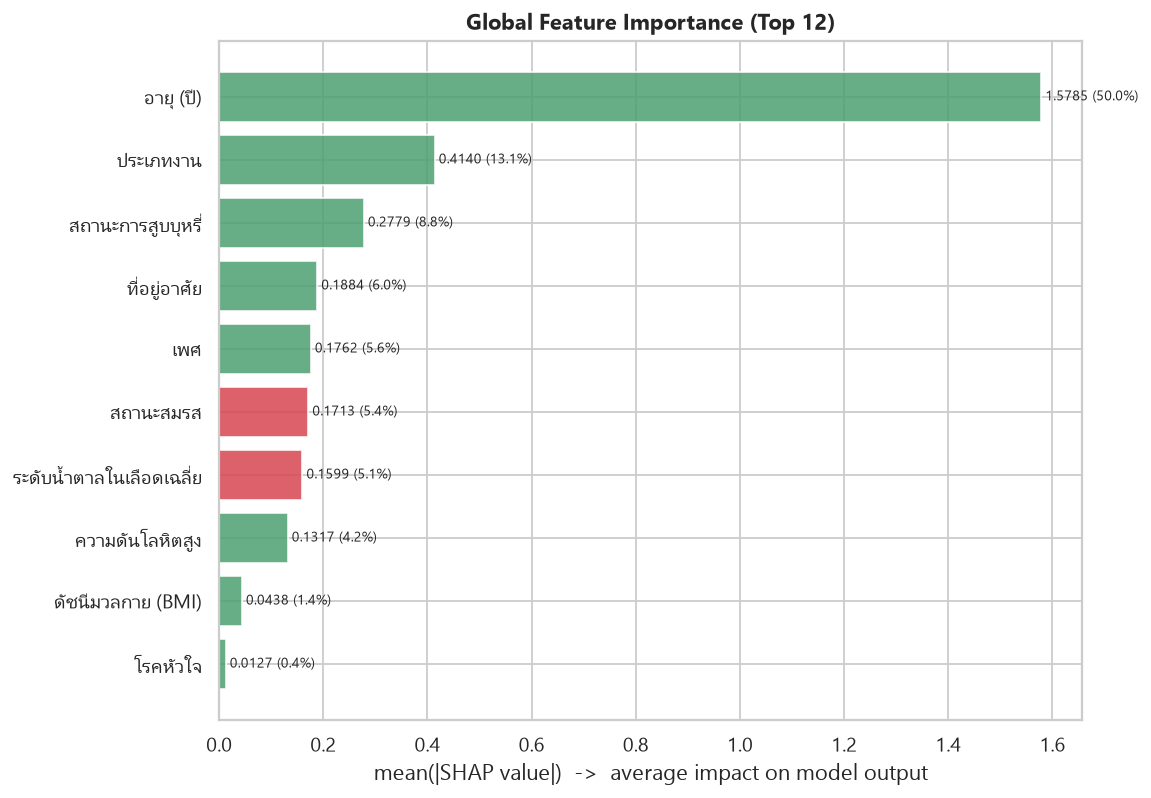

In [7]:
show_figure("xai/20_shap_bar.png", 950)

**อ่านค่า**: `mean(|SHAP|)` คือขนาดอิทธิพลเฉลี่ย และ `importance_pct` คือสัดส่วน
เมื่อเทียบกับอิทธิพลรวมทั้งหมด → บอกได้ว่าแต่ละฟีเจอร์ "แบก" การทำนายไว้กี่เปอร์เซ็นต์

> **Insight Q4.1** — **อายุ (age)** มีอิทธิพลสูงสุดอย่างชัดเจน (มักครองสัดส่วนสูงที่สุด
> ของอิทธิพลรวมทั้งหมด) สอดคล้องกับการทดสอบทางสถิติในเล่ม 02 (rank-biserial สูงสุด)
> แสดงว่า **หลักฐานเชิงสถิติและพฤติกรรมของโมเดลสอดคล้องกัน** — เป็นสัญญาณที่ดี
> ว่าคำอธิบายที่ได้น่าเชื่อถือ

### 🚨 กับดักสำคัญ: ฟีเจอร์ไบนารีที่หายาก

`mean(|SHAP|)` **เอนเอียงเข้าข้างฟีเจอร์ที่พบบ่อย**

ตัวอย่าง: `heart_disease` พบเพียง ~5% ของ records → อีก ~95% contribution เป็น 0
ค่า `mean(|SHAP|)` จึงต่ำมาก **ทั้งที่เมื่อพบผู้ป่วยโรคหัวใจจริง อิทธิพลต่อการทำนายสูง**
(สอดคล้องกับ Odds Ratio ≈ 4.7 จากเล่ม 02)

**วิธีแก้ที่ถูกต้อง** — รายงานอิทธิพลเฉพาะเมื่อฟีเจอร์ "เปิด" เพิ่มด้วย

In [8]:
imp = importance.copy()
imp["rank_overall"] = imp["mean_abs_shap"].rank(ascending=False).astype(int)

# แนวคิด "เปิด/ปิด" ใช้ได้เฉพาะตัวแปรไบนารี -> เทียบเฉพาะกลุ่มนี้
binary = imp[imp["feature"].isin(cfg.BINARY_FEATURES)].copy()
binary["rank_when_active"] = binary["mean_abs_shap_when_active"].rank(ascending=False).astype(int)

print(f"=== ตัวแปรไบนารี {len(binary)} ตัว: อันดับโดยรวม vs อันดับเมื่อ 'เปิด' ===")
display(binary[["feature", "rank_overall", "mean_abs_shap", "pct_records_active",
                "rank_when_active", "mean_abs_shap_when_active"]]
        .sort_values("rank_overall"))

print(f"=== ตารางรวมทั้งหมด {len(imp)} ฟีเจอร์ (เรียงตาม mean|SHAP|) ===")
display(imp[["rank_overall", "feature", "mean_abs_shap", "importance_pct"]])

=== ตัวแปรไบนารี 2 ตัว: อันดับโดยรวม vs อันดับเมื่อ 'เปิด' ===


,feature,rank_overall,mean_abs_shap,pct_records_active,rank_when_active,mean_abs_shap_when_active
7,hypertension,8,0.143164,13.33,1,0.5447
9,heart_disease,10,0.014079,5.33,2,0.1365


=== ตารางรวมทั้งหมด 10 ฟีเจอร์ (เรียงตาม mean|SHAP|) ===


,rank_overall,feature,mean_abs_shap,importance_pct
0,1,age,1.573097,49.94
1,2,work_type,0.411499,13.06
2,3,smoking_status,0.278217,8.83
3,4,Residence_type,0.190848,6.06
4,5,gender,0.173128,5.50
5,6,ever_married,0.168098,5.34
6,7,avg_glucose_level,0.156829,4.98
7,8,hypertension,0.143164,4.55
8,9,bmi,0.040781,1.29
9,10,heart_disease,0.014079,0.45


> **Insight Q4.2** — `heart_disease` อยู่ **อันดับสุดท้าย** เมื่อดู `mean(|SHAP|)` โดยรวม
> (เพราะมีเพียง ~4% ของ records ที่ "เปิด") แต่ **ไต่ขึ้นมาเมื่อดูเฉพาะเมื่อเปิด**
> ในทางกลับกัน `hypertension` (เปิด ~11%) ก็ขยับขึ้นเช่นกัน
>
> 👉 **บทเรียน**: `mean(|SHAP|)` ตอบคำถามว่า *"ฟีเจอร์นี้มีอิทธิพลต่อการทำนายของ
> ประชากรทั้งหมดแค่ไหน"* แต่ไม่ตอบคำถามที่แพทย์สนใจว่า
> *"ถ้าผู้ป่วยรายนี้มีปัจจัยเสี่ยงนี้ อิทธิพลมันแรงแค่ไหน"*
> → ต้องรายงานทั้งสองมุมมองคู่กันเสมอ ไม่งั้นจะตีความผิดว่าปัจจัยเสี่ยงที่พบน้อย "ไม่สำคัญ"
>
> (ตัวแปรต่อเนื่องและตัวแปรเชิงกลุ่มไม่ใช้แนวคิดนี้ — ค่าที่เป็น 0 ยังมีความหมาย
> จึงอ่านผ่าน `mean(|SHAP|)` และ beeswarm แทน)

## 4. Beeswarm — ทิศทางของอิทธิพล

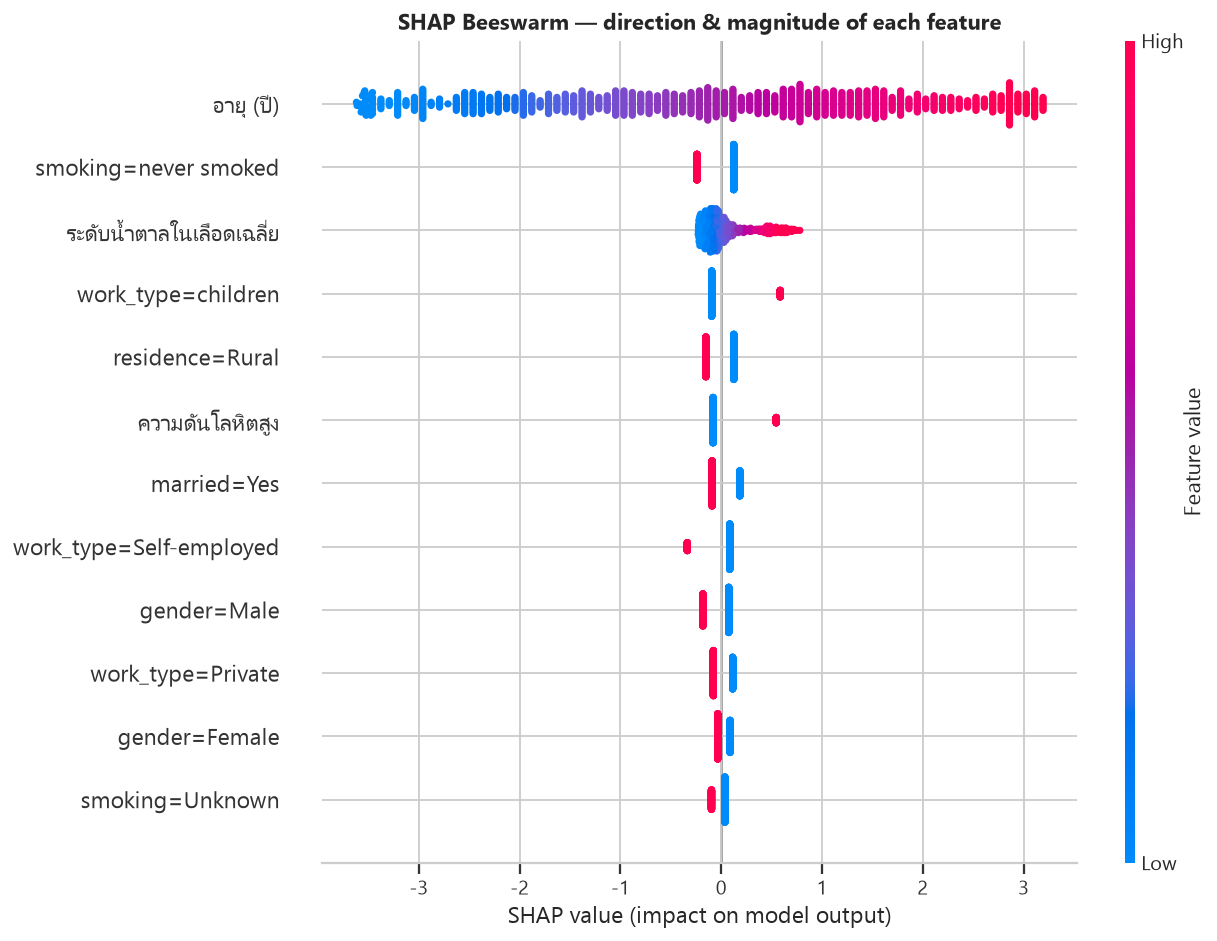

In [9]:
show_figure("xai/21_shap_beeswarm.png", 1000)

**วิธีอ่าน beeswarm**: แต่ละจุด = 1 record
- แกน X = ค่า SHAP (ซ้าย = ดันไปทางไม่เป็น stroke, ขวา = ดันไปทางเป็น stroke)
- สี = ค่าจริงของฟีเจอร์นั้น (แดง = ค่าสูง, น้ำเงิน = ค่าต่ำ)

ถ้าจุดสีแดง (ค่าสูง) กระจุกอยู่ทางขวา → ฟีเจอร์นั้น "ยิ่งค่าสูง ยิ่งเพิ่มความเสี่ยง"

### 🔎 ปรากฏการณ์น่าสนใจ: sign flip จาก confounding

ลองสังเกตฟีเจอร์ที่มีค่าเฉลี่ย SHAP (`mean_shap`) **ตรงข้าม** กับผลการทดสอบสถิติในเล่ม 02
เช่น `ever_married`:

- **การทดสอบทางสถิติ**: คนที่สมรสแล้วมีอัตรา stroke สูงกว่า (มีนัยสำคัญ)
- **SHAP ของโมเดล**: ค่าเฉลี่ยอาจกลับเป็น **ลบ** (ดันไปทาง "ไม่เป็น stroke")

สาเหตุคือ **confounding by age** — โมเดลเห็น `age` อยู่แล้ว จึงหักอิทธิพลของอายุออกไป
และพบว่าในกลุ่มคนอายุเท่ากัน การสมรสไม่ได้เพิ่มความเสี่ยง (อาจให้ผลป้องกันด้วยซ้ำ)

> 👉 นี่คือตัวอย่างของ **Simpson's paradox** และเป็นเหตุผลว่าทำไม
> **คำอธิบายของโมเดล ≠ ความสัมพันธ์ดิบในข้อมูล** — ทั้งสองถูกต้องแต่ตอบคนละคำถาม

## 5. Local explanation — ทำไม record นี้จึงถูกทำนายเช่นนั้น

In [10]:
local = pd.read_csv(cfg.TABLES_DIR / "q4_shap_local_cases.csv")
cases = local["case"].unique()
print("เคสที่มีให้อธิบาย:", list(cases))
local.head(12)

เคสที่มีให้อธิบาย: ['TP (ทำนายถูก-เป็น stroke)', 'FN (พลาดผู้ป่วยจริง)', 'FP (เตือนเกิน)']


,case,record_index,feature,shap_value,direction,raw_value,predicted_prob,actual
0,TP (ทำนายถูก-เป็น stroke),137,age,2.6935,ดันให้เป็น stroke,76.0,0.8855,1
1,TP (ทำนายถูก-เป็น stroke),137,avg_glucose_level,0.4933,ดันให้เป็น stroke,207.28,0.8855,1
2,TP (ทำนายถูก-เป็น stroke),137,hypertension,-0.0814,ดันให้ไม่เป็น stroke,0,0.8855,1
3,TP (ทำนายถูก-เป็น stroke),137,Residence_type,0.0789,ดันให้เป็น stroke,Urban,0.8855,1
4,TP (ทำนายถูก-เป็น stroke),137,work_type,-0.0740,ดันให้ไม่เป็น stroke,Private,0.8855,1
5,TP (ทำนายถูก-เป็น stroke),137,ever_married,-0.0567,ดันให้ไม่เป็น stroke,Yes,0.8855,1
6,TP (ทำนายถูก-เป็น stroke),137,bmi,0.0454,ดันให้เป็น stroke,34.9,0.8855,1
7,TP (ทำนายถูก-เป็น stroke),137,gender,0.0388,ดันให้เป็น stroke,Female,0.8855,1
8,TP (ทำนายถูก-เป็น stroke),137,heart_disease,-0.0072,ดันให้ไม่เป็น stroke,0,0.8855,1
9,TP (ทำนายถูก-เป็น stroke),137,smoking_status,0.0069,ดันให้เป็น stroke,Unknown,0.8855,1


In [11]:
# เลือกเคส False Negative — ผู้ป่วยจริงที่โมเดลมองข้าม (น่ากังวลที่สุดทางคลินิก)
case = "FN (พลาดผู้ป่วยจริง)" if "FN (พลาดผู้ป่วยจริง)" in cases else cases[0]
sub = local[local["case"] == case].sort_values("shap_value")
rec = sub["record_index"].iloc[0]
view = sub[sub["record_index"] == rec][["feature", "raw_value", "shap_value", "direction", "predicted_prob"]]
print(f"เคส: {case} | record #{rec}")
view

เคส: FN (พลาดผู้ป่วยจริง) | record #133


,feature,raw_value,shap_value,direction,predicted_prob
10,age,38.0,-0.4662,ดันให้ไม่เป็น stroke,0.1482
12,Residence_type,Rural,-0.0964,ดันให้ไม่เป็น stroke,0.1482
13,hypertension,0,-0.0814,ดันให้ไม่เป็น stroke,0.1482
14,work_type,Private,-0.0740,ดันให้ไม่เป็น stroke,0.1482
15,ever_married,Yes,-0.0567,ดันให้ไม่เป็น stroke,0.1482
17,avg_glucose_level,101.45,-0.0084,ดันให้ไม่เป็น stroke,0.1482
18,heart_disease,0,-0.0072,ดันให้ไม่เป็น stroke,0.1482
19,bmi,NaN,-0.0066,ดันให้ไม่เป็น stroke,0.1482
16,gender,Female,0.0388,ดันให้เป็น stroke,0.1482
11,smoking_status,formerly smoked,0.1013,ดันให้เป็น stroke,0.1482


**วิธีแนะนำให้อ่าน**: ไล่จาก SHAP ที่เป็นลบมากที่สุด (ดันให้ "ไม่เป็น stroke")
ไปหาบวกมากที่สุด แล้วถามว่า "ถ้าฟีเจอร์นี้เปลี่ยนไป คำตอบจะพลิกไหม"

### SHAP Waterfall ของ 3 เคสตัวแทน

- **TP (True Positive)** — โมเดลจับผู้ป่วยได้ → ดูว่าโมเดล "เห็น" อะไร
- **FN (False Negative)** — โมเดลพลาด → ดูว่าโมเดล "ตีความผิด" ตรงไหน
- **FP (False Positive)** — เตือนเกิน → ดูว่าโมเดลตื่นตระหนกกับอะไร

--- TP ---


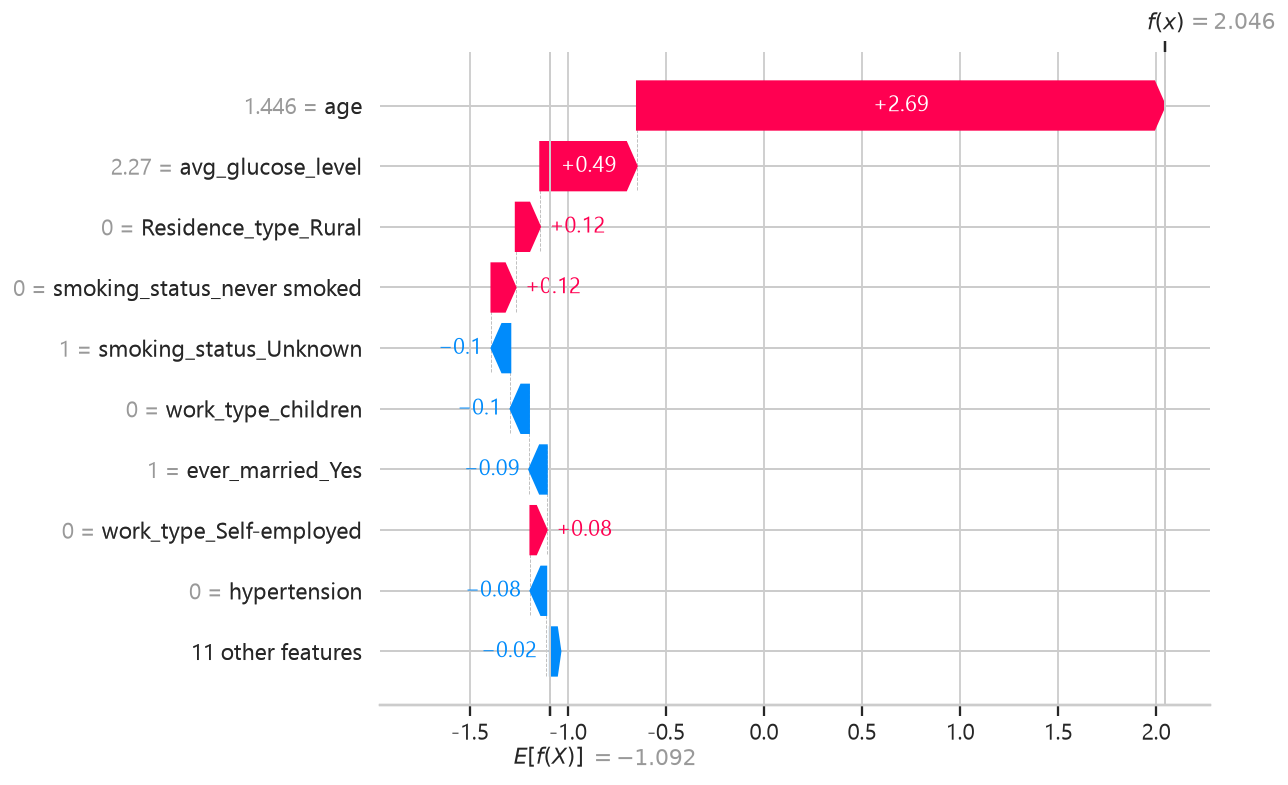

--- FN ---


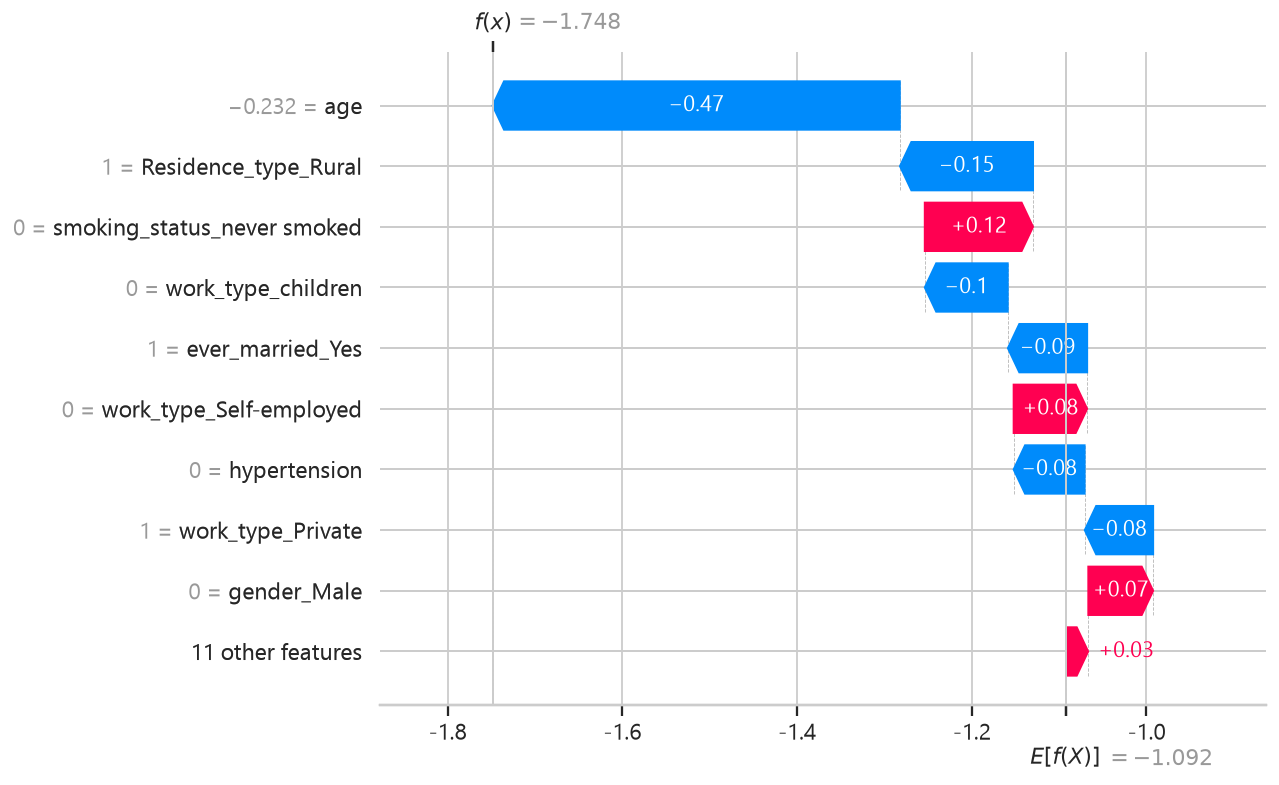

--- FP ---


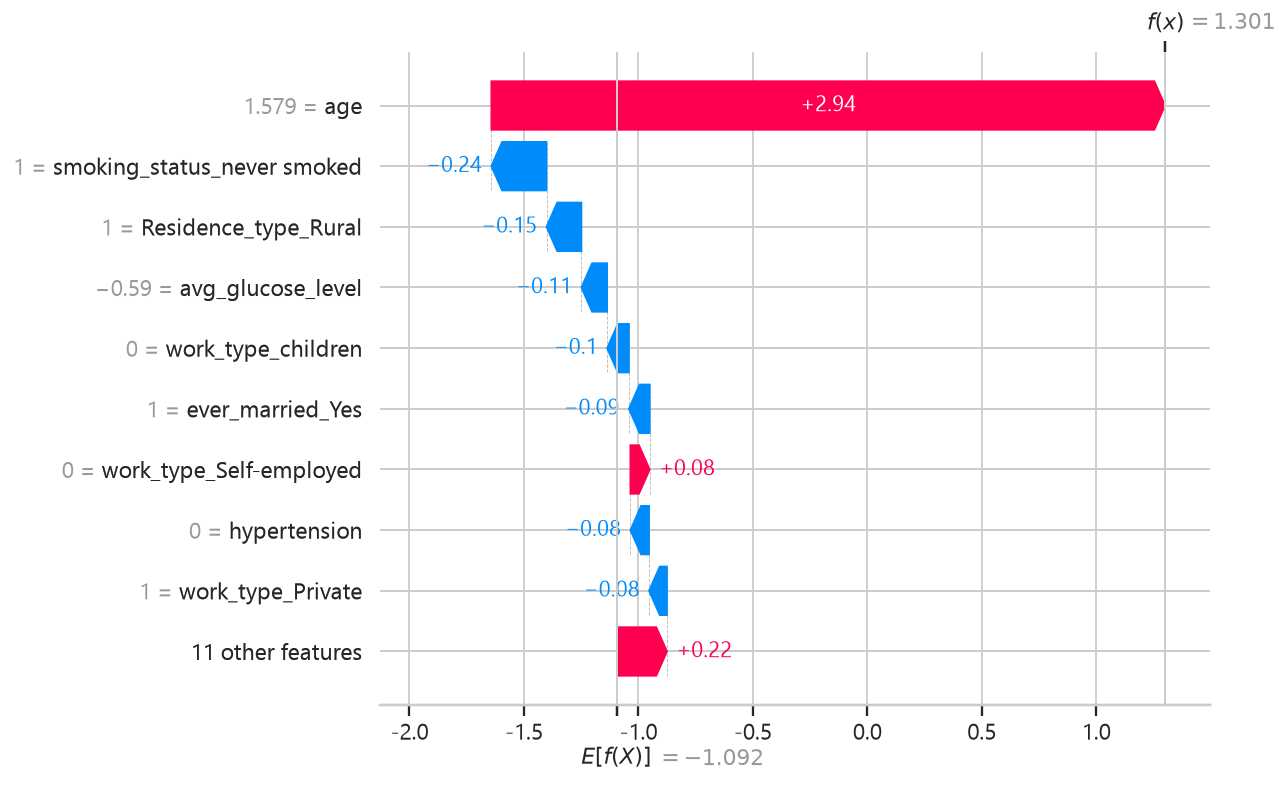

In [12]:
from IPython.display import Image, display

for tag in ["TP", "FN", "FP"]:
    matches = sorted((cfg.FIGURES_DIR / "xai").glob(f"22_shap_waterfall_{tag}*.png"))
    for m in matches:
        print(f"--- {tag} ---")
        display(Image(filename=str(m), width=900))

## 6. ข้อจำกัดของ SHAP ที่ต้องรายงาน

1. **SHAP อธิบายโมเดล ไม่ได้อธิบายโรค** — ค่า SHAP คือ "โมเดลใช้ฟีเจอร์นี้อย่างไร"
   ไม่ใช่ "ฟีเจอร์นี้ทำให้เกิดโรค"
2. **ฟีเจอร์ correlated** (เช่น age กับ ever_married) จะแชร์อิทธิพลกันแบบไม่แน่นอน
   ทำให้ค่า SHAP ของแต่ละตัวผันผวนได้
3. **ค่า SHAP ขึ้นกับ background dataset** — ถ้าเปลี่ยนชุดอ้างอิง ค่าที่ได้จะเปลี่ยน
4. **one-hot grouping** เป็นการประมาณ (ยกเว้น categorical ที่เป็น mutually exclusive จริง)

## 7. สรุป Q4

- **Global**: `age` คือปัจจัยที่ขับเคลื่อนการทำนายสูงสุดอย่างชัดเจน รองลงมาคือ
  กลุ่มฟีเจอร์เชิงกลุ่มที่ correlated กับอายุ (`work_type`, `ever_married`) และ
  `avg_glucose_level` — **สอดคล้องกับ Q1** ซึ่งเป็นหลักฐานว่าโมเดลเรียนรู้แบบแผนจริง
  ไม่ได้เรียนรู้ noise
- **Local**: โมเดลใช้ "การผสมกัน" ของหลายฟีเจอร์ ไม่ได้ตัดสินจากฟีเจอร์เดียว
  เคส FN มักเป็นผู้ป่วยที่มีความเสี่ยงไม่เด่นชัด — แบบแผนเดียวกับกลุ่มที่
  การทดสอบทางสถิติก็จับได้ยาก
- **กับดัก**: `mean(|SHAP|)` เอนเอียงเข้าข้างฟีเจอร์ที่พบบ่อย ต้องรายงาน
  `mean_abs_shap_when_active` คู่กันเสมอสำหรับฟีเจอร์ไบนารีที่หายาก
- **Confounding**: อิทธิพลของฟีเจอร์บางตัว **กลับเครื่องหมาย** เมื่อเทียบกับ
  ความสัมพันธ์ดิบ เพราะโมเดลควบคุมอิทธิพลของอายุแล้ว — เป็นจุดที่ต้องอธิบายให้ชัด
  ว่า "คำอธิบายของโมเดล" กับ "ความสัมพันธ์ทางสถิติ" ตอบคนละคำถาม